# CITY OF CALGARY TRANSIT ANALYSIS

## Goal

Transit usage is highly dependant on its efficacy, i.e., ones ability to get across the city that maximizes some time-cost optimization. Increasing the efficacy of public transit has impacts across multiple areas: social mobility, reducing gridlock, reducing emissions, etc.

A first step in such an analysis is to establish the connectedness of the transit network - starting from stop A, how easily can I get to point B, for the city center.

## Approach

This work-in-progress notebook takes a step-by-step approach:

1) How are bus stops distributed across the city? How many stops per resident of the community?
2) How accessible is Calgary LRT (c-train) from a given community?
    - Part 1: A simple distance-based analysis. This is a proxy for riders ability to get to LRT by car.
    - Part 2: Accessbility by bus. Stops near LRT stations are identified and we analyze the average number of stops one needs to get from their community to the nearest LRT station. (work-in-progress)
3) How accessible is Downtown from a given community via Transit?
    - Requires part 2 to be finished.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx



In [ ]:
#LOCAL HELPER FUNCTIONS AND PARAMETERS


#--------- FUNCTIONS

def get_grouped_dtypes(gdf):
    """
    Returns a dictionary of grouped data types for a GeoDataFrame (or DataFrame).
    
    Parameters:
    gdf (GeoDataFrame): The input GeoDataFrame.
    
    Returns:
    dict: A dictionary where keys are data types and values are lists of column names with that data type.
    """
    grouped_dtypes = gdf.columns.to_series().groupby(gdf.dtypes, sort=False).groups

    for dtype, cols in grouped_dtypes.items():
        print(f"\n--- {dtype} ({len(cols)}) ---")
        print(list(cols))
    return

def flatten(nested_list):
  """
  Flattens a list of arbitrary shape

  Parameters:
  nested_list: a list of potentially nested lists

  Returns:
  flat: a single flat list containing the elements in the nested lists (with potential repeats included)

  """
  flat = []
  for item in nested_list:
    if isinstance(item, list):
      flat.extend(flatten(item))
    else:
      flat.append(item)
  return flat



#--------- PARAMETERS

#Calgarys internal coordinate uses epsg 3776
EPSG = 3776

#Defaul Tiles Map
DEFAULT_TILES = "Esri.WorldGrayCanvas"


#we will say two stops are 'near' each other if they are within this range
MAX_DISTANCE = 200 #(m)

#Data
STOPS_GJSON = './data/Calgary_Transit_Stops_20261123.geojson'
CENSUS_GJSON = './data/Census_by_Community_2019_20261123.geojson'
LRT_GJSON = './data/Transit_LRT_Stations_20261124.geojson'




# How are bus stops distributed across the city?

LOAD CHECK AND CLEAN STOPS_GDF

In [ ]:
stops_gdf = gpd.read_file(STOPS_GJSON)

#check data types
print(get_grouped_dtypes(stops_gdf))

#convert teleride_number to number
stops_gdf['teleride_number'] =  stops_gdf['teleride_number'].astype(int)

#filter out inactive stopsscree
stops_gdf = stops_gdf[stops_gdf['status'] == 'ACTIVE']

#check the data types and null values again after filtering
if stops_gdf.isnull().any().any():
    print("There are null values in the GeoDataFrame.")
    print(stops_gdf.isnull().sum())

#convert gdf from degrees to local metres 
stops_proj = stops_gdf[['teleride_number', 'geometry', 'stop_name']].to_crs(epsg=EPSG)



--- str (10) ---
[':id', ':version', 'teleride_number', 'stop_name', 'status', 'globalid', ':@computed_region_4b54_tmc4', ':@computed_region_kxmf_bzkv', ':@computed_region_4a3i_ccfj', ':@computed_region_p8tp_5dkv']

--- datetime64[ms, UTC] (4) ---
[':created_at', ':updated_at', 'create_dt_utc', 'mod_dt_utc']

--- geometry (1) ---
['geometry']
None
There are null values in the GeoDataFrame.
:id                             0
:version                        0
:created_at                     0
:updated_at                     0
teleride_number                 0
stop_name                       0
status                          0
create_dt_utc                   0
mod_dt_utc                      0
globalid                        0
:@computed_region_4b54_tmc4    14
:@computed_region_kxmf_bzkv    14
:@computed_region_4a3i_ccfj    14
:@computed_region_p8tp_5dkv    14
geometry                        0
dtype: int64


## For each stop, calculate number of stops within a max_distance m distance

In [ ]:
# Query the spatial index for all pairs within max_distance
# Returns a 2xM array: [source_indices, neighbor_indices]

src_idx, nbr_idx = stops_proj.sindex.query(
    stops_proj.geometry, 
    predicate="dwithin", 
    distance=max_distance 
)

# Exclude self-matches
mask = src_idx != nbr_idx
src_idx = src_idx[mask]

# for each stop count number of stops within max_distance = counting number of times stop appears in src_idx
# minlength ensures points with 0 neighbors still get a count of 0
counts = np.bincount(src_idx, minlength=len(stops_proj))

# 4. Assign back to your GeoDataFrame
stops_proj["neighbour_count"] = counts




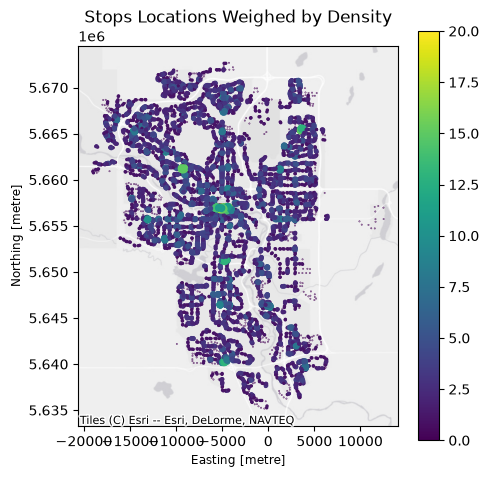

In [ ]:
plt.figure(figsize=(5,5))

#plot the stops within threshold distance
stops_proj.plot('neighbour_count', 
                tiles = DEFAULT_TILES, 
                markersize=2*stops_proj['neighbour_count'] + .1, #add .1 to include non-dense stops
                legend= True,
                ax=plt.gca())
plt.title('Stops Locations Weighed by Density')

# for i in range(1, n_rows * n_cols + 1):
#     plt.subplot(n_rows, n_cols, i)  
#     plt.xticks([])
#     plt.yticks([])
#     plt.xlabel('')
#     plt.ylabel('')
#     plt.box(False)

plt.tight_layout()


In [ ]:
#LOAD, CHECK, AND CLEAN CENSUS DATA

#load census data
census_gdf = gpd.read_file(CENSUS_GJSON)

get_grouped_dtypes(census_gdf)

#counts appear to be stored as strings, we should convert any column with '_cnt' to numeric
for col in census_gdf.columns:
    if col.endswith('_cnt'):
        census_gdf[col] = pd.to_numeric(census_gdf[col], errors='coerce')


#local projection, only for the columns we need for analysis
cols_to_keep = ['res_cnt', 'cat_cnt', 'dog_cnt', 'geometry', 'name']
census_proj = census_gdf[cols_to_keep].to_crs(epsg=EPSG)



In [ ]:
#calculate the area and residence density for each community
census_proj['area'] = census_proj['geometry'].area
census_proj['res_density'] = census_proj['res_cnt'] / census_proj['area']

#get the community name each stop is in with sjoin
stops_proj = gpd.sjoin(stops_proj, census_proj[['name', 'geometry']], how='left', predicate = 'within').drop(columns="index_right")

#get the number of stops within each community from stops_proj and add it as column to census_proj
stop_counts = stops_proj.groupby('name').size().reset_index(name='stop_count')
census_proj = census_proj.merge(stop_counts, on='name', how='left')

#calculate the stop density for each community
census_proj['stop_density'] = census_proj['stop_count'] / census_proj['area']


In [ ]:


n_rows = 3
n_cols = 2
plt_index = 0

plt.figure(figsize=(4*n_cols,4*n_rows))



#plot the stops
plt_index += 1
plt.subplot(n_rows, n_cols, plt_index)
stops_proj.plot(tiles = True, markersize=2, ax=plt.gca())
plt.title('Stops')

#plot the stops within threshold distance
plt_index += 1
plt.subplot(n_rows, n_cols, plt_index)
stops_proj.plot('neighbour_count', tiles = True, markersize=stops_proj['neighbour_count'], ax=plt.gca())
plt.title('Stops Within 500 m')

#plot the res_cnt by community
plt_index += 1
plt.subplot(n_rows, n_cols, plt_index)
census_proj.plot('res_cnt', ax=plt.gca())
plt.title('Residential Count')

#plot the area by community
plt_index += 1
plt.subplot(n_rows, n_cols, plt_index)
census_proj.plot('area', ax=plt.gca())
plt.title('Area (square meters)')

#plot the density
plt_index += 1
plt.subplot(n_rows, n_cols, plt_index)
census_proj.plot('res_density', ax=plt.gca())
plt.title('Residential Density')

#plot the stop density
plt_index += 1
plt.subplot(n_rows, n_cols, plt_index)
census_proj.plot('stop_density', ax = plt.gca())
plt.title('Stop Density')
plt.gca().set_frame_on(False)

for i in range(1, n_rows * n_cols + 1):
    plt.subplot(n_rows, n_cols, i)  
    plt.xticks([])
    plt.yticks([])
    plt.xlabel('')
    plt.ylabel('')
    plt.box(False)

plt.tight_layout()

# LRT

The above analysis only considers bus stops. However, the c-train is a vital artery into downtown. Below we load LRT data from LRT_GJSON. Our first goal is to find the distance of each community to the nearest LRT station, which is important as many riders first drive to an LRT and then take LRT downtown. 

### Limitations
The current approach consideres strictly straight-line (Euclidean) distance. It does *not* consider the actual roads, and as such may not be accurate around major geographic features such as the river and nose-hill park. Will be addressed in the future.

### Future considerations
The MAX bus routes are are fast, low-stop routes meant to act as an cost-effective alternative to building out LRT lines. These are not yet considered but should be kept in mind for future analysi.

In [306]:
#LOAD, CHECK, AND CLEAN LRT DATA

lrt_gpd = gpd.read_file(LRT_GJSON)
print(get_grouped_dtypes(lrt_gpd))

lrt_proj = lrt_gpd.to_crs(epsg = EPSG)


--- str (15) ---
[':id', ':version', 'stationnam', 'leg', 'direction', 'dist_nb', 'dist_sb', 'dist_eb', 'dist_wb', 'route', 'status', ':@computed_region_4b54_tmc4', ':@computed_region_4a3i_ccfj', ':@computed_region_kxmf_bzkv', ':@computed_region_p8tp_5dkv']

--- datetime64[ms, UTC] (2) ---
[':created_at', ':updated_at']

--- geometry (1) ---
['geometry']
None


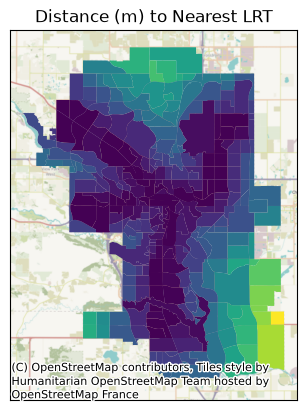

In [307]:
# Find community centroid
census_proj['centroid'] = census_proj.centroid

# Get the LRT station closest to the community centroid, and calculate the distance
nearest_proj = gpd.sjoin_nearest(census_proj, 
                                 lrt_proj[['stationnam', 'geometry']],
                                 how = 'left',
                                 distance_col="distance_meters")

nearest_proj.plot('distance_meters', tiles = True)
plt.xlabel('')
plt.ylabel('')
plt.xticks([])
plt.yticks([])
plt.title('Distance (m) to Nearest LRT')
plt.show()


# LRT Accessibility via Public Transit

The above analysis shows approximate community accessibility to LRT. However, without the building of new roads or LRT stations, the map is immutible.

Next we ask: how accessible are LRT stations by local bus routes?

## Approach

First we identify the stops that are within some distance of an LRT station, which we will call 'LRT stops'. This will be used to later to see connected each community is to an LRT stop.

In [312]:
#FIND BUS STOPS WITHIN max_distance OF LRT STATIONS

#finds the stops
max_distance = 200 #meters
src_idx, nbr_idx = lrt_proj.sindex.query(
    stops_proj.geometry, 
    predicate="dwithin", 
    distance=max_distance
)


#For each row in lrt_proj we will add a new column containing a list of stops (by teleride_number) that are within max_distance of the station.
near_by_stops = list()
rows_to_keep = list()
for i,row in enumerate(lrt_proj.iloc):

    #lrt index
    idx = np.where(nbr_idx == i)
    #get all the rows in stops_proj for filtering
    rows_to_keep.append(list(src_idx[idx[0]]))
    #get all the stop teleride numbers near the lrt
    stop_ids = list(stops_proj['teleride_number'].iloc[idx])
    near_by_stops.append((stop_ids))
    

lrt_proj['near_by_teleride_number'] = near_by_stops
lrt_proj['num_nearby_stops'] = [len(x) for x in (near_by_stops)]

#make a dataframe containing only LRT stops
rows_to_keep = list(set(flatten(rows_to_keep)))
lrtstops_proj = stops_proj.iloc[rows_to_keep]

<Figure size 1000x1000 with 0 Axes>

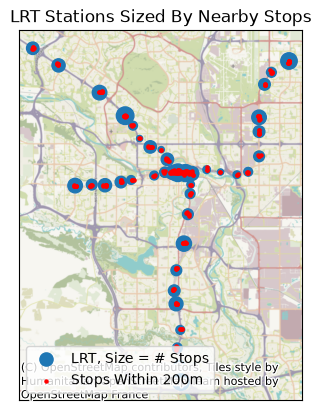

In [313]:
#plot the nearby stops in red. Size LRT stations according to the number of stops they have around them

plt.figure(figsize=(10,10))
lrt_proj.plot(markersize= 10*(lrt_proj['num_nearby_stops']), label = 'LRT, Size = # Stops')
lrtstops_proj.plot(markersize=5, color='r', ax = plt.gca(), tiles = True, label = 'Stops Within ' + str(max_distance) + 'm')
plt.legend(loc="lower left")
plt.xlabel('')
plt.ylabel('')
plt.xticks([])
plt.yticks([])
plt.title('LRT Stations Sized By Nearby Stops')
plt.show()
# Add caption at the bottom center of the figure


# Network Approach Community LRT Accessibility

## General Approach
An LRT station is accessible to a community if a route within the community reaches a stop near an LRT station. This is essentially a walk on a network. 

### Methods
Nodes: stops. Stops will be partitioned into two groups: 1) regular stops, 2) LRT stops.
Links: two stops are linked if a route connects them. 

Metric: mean number of minimum stops to an LRT stop, averaged across all stops in the community. 

### IN PROGRESS